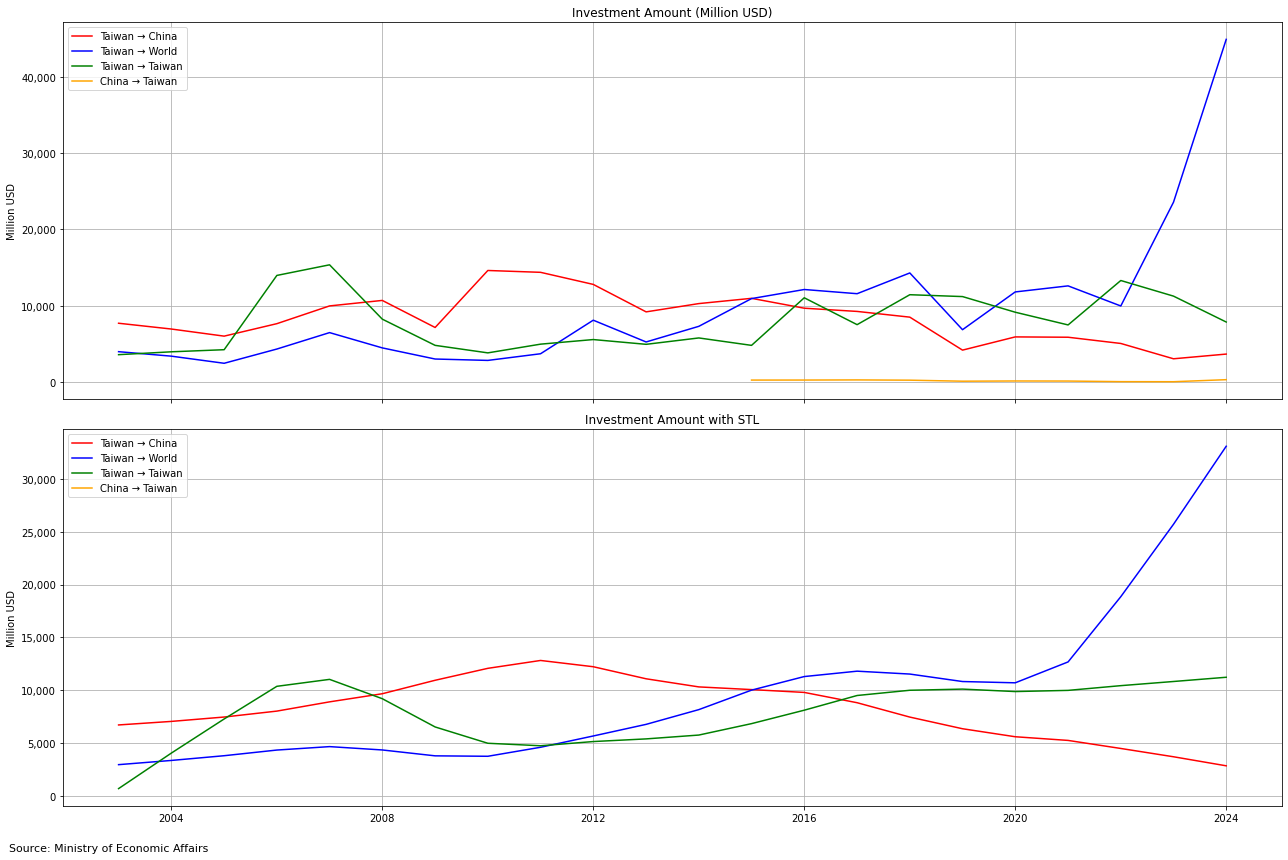

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from matplotlib.ticker import FuncFormatter

file_path = "investment data.xlsx"

china = pd.read_excel(file_path, usecols="A:C", skiprows=1, nrows=23)
world = pd.read_excel(file_path, usecols="E:G", skiprows=1, nrows=23)
taiwan = pd.read_excel(file_path, usecols="I:K", skiprows=1, nrows=23)
from_china = pd.read_excel(file_path, usecols="M:O", skiprows=1, nrows=10)  # 2015–2024

china.columns = ["Year", "Taiwan → China", "Taiwan → China (Count)"]
world.columns = ["Year", "Taiwan → World", "Taiwan → World (Count)"]
taiwan.columns = ["Year", "Taiwan → Taiwan", "Taiwan → Taiwan (Count)"]
from_china.columns = ["Year", "China → Taiwan", "China → Taiwan (Count)"]

df = china.copy()
df["Taiwan → World"] = world["Taiwan → World"]
df["Taiwan → World (Count)"] = world["Taiwan → World (Count)"]
df["Taiwan → Taiwan"] = taiwan["Taiwan → Taiwan"]
df["Taiwan → Taiwan (Count)"] = taiwan["Taiwan → Taiwan (Count)"]

df = df.merge(from_china, on="Year", how="left")

df["Date"] = pd.to_datetime(df["Year"], format="%Y")
df.set_index("Date", inplace=True)

color_map = {"Taiwan → China": "red", "Taiwan → World": "blue", "Taiwan → Taiwan": "green", "China → Taiwan": "orange"}

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")

fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharex=True)

for col in color_map:
    axes[0].plot(df.index, df[col], label=col, color=color_map[col])
axes[0].set_title("Investment Amount (Million USD)")
axes[0].set_ylabel("Million USD")
axes[0].legend()
axes[0].grid(True)
axes[0].yaxis.set_major_formatter(formatter)

for col in color_map:
    series = df[col].asfreq("YS")
    if series.notna().sum() >= 4:
        trend = STL(series, period=3).fit().trend
        axes[1].plot(trend.index, trend, label=col, color=color_map[col])
axes[1].set_title("Investment Amount with STL")
axes[1].set_ylabel("Million USD")
axes[1].legend()
axes[1].grid(True)
axes[1].yaxis.set_major_formatter(formatter)

plt.figtext(0.01, 0.01, "Source: Ministry of Economic Affairs", ha='left', fontsize=11)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()


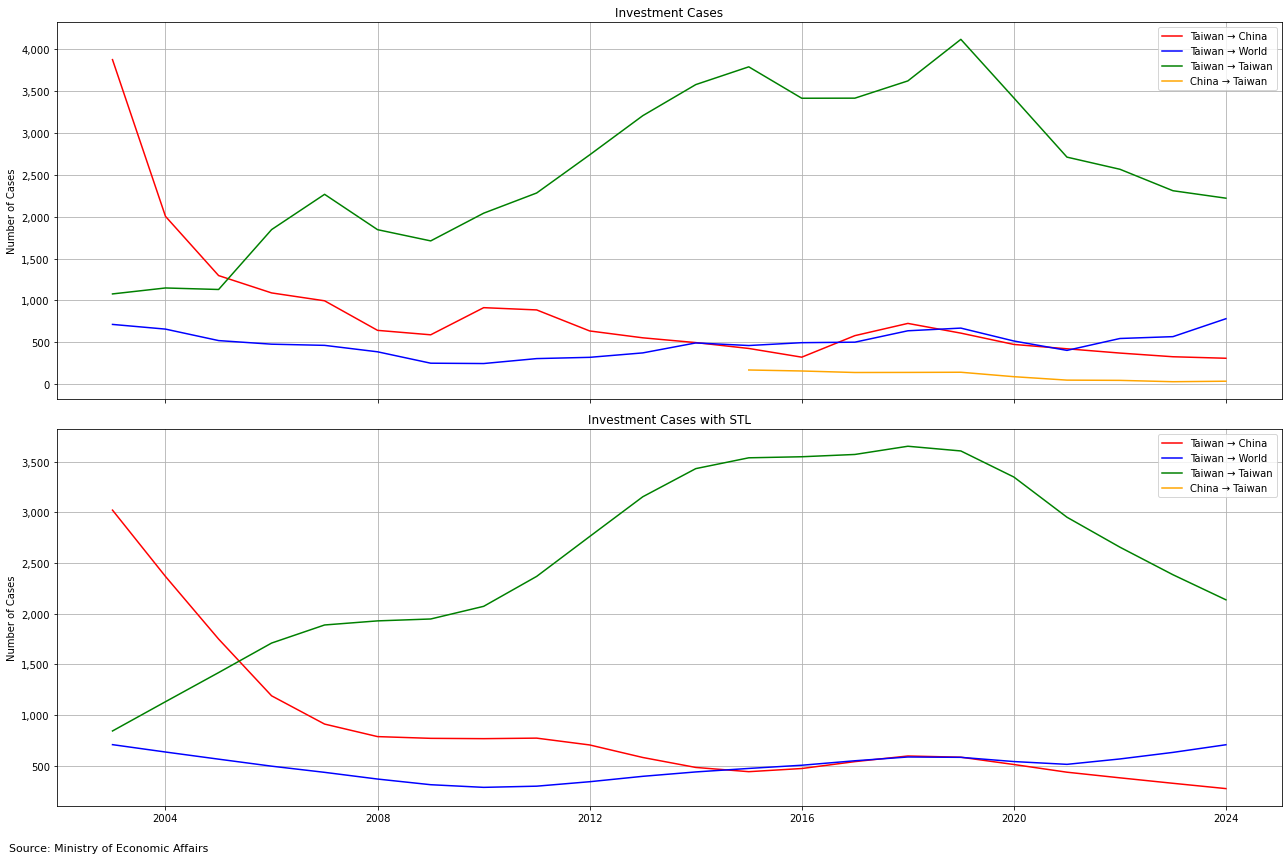

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharex=True)

for col in ["Taiwan → China (Count)", "Taiwan → World (Count)", "Taiwan → Taiwan (Count)", "China → Taiwan (Count)"]:
    label = col.replace(" (Count)", "")
    axes[0].plot(df.index, df[col], label=label, color=color_map[label])
axes[0].set_title("Investment Cases")
axes[0].set_ylabel("Number of Cases")
axes[0].legend()
axes[0].grid(True)
axes[0].yaxis.set_major_formatter(formatter)

for col in ["Taiwan → China (Count)", "Taiwan → World (Count)", "Taiwan → Taiwan (Count)", "China → Taiwan (Count)"]:
    label = col.replace(" (Count)", "")
    series = df[col].asfreq("YS")
    if series.notna().sum() >= 4:
        trend = STL(series, period=3).fit().trend
        axes[1].plot(trend.index, trend, label=label, color=color_map[label])
axes[1].set_title("Investment Cases with STL")
axes[1].set_ylabel("Number of Cases")
axes[1].legend()
axes[1].grid(True)
axes[1].yaxis.set_major_formatter(formatter)

plt.figtext(0.01, 0.01, "Source: Ministry of Economic Affairs", ha='left', fontsize=11)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()